# 01 - Score distributions and ceiling indicators (2020-2026)

Source: NAEC equating tables (`Stats_YYYY.xlsx`): number of test-takers at each raw score,
per subject, year and exam version.

Ceiling indicators (computed per exam version, then averaged across versions weighted by N):
- `pct_max`: % of test-takers at the maximum raw score.
- `pct_top3`: % of test-takers in the top 3 raw-score points (max, max-1, max-2).
- `pts_top1pct` / `pts_top5pct`: how many raw-score points the top 1% / top 5% of test-takers
  are spread over (resolution at the top; 1 = everybody in the top 1% has the same score).
- `tail_flatness`: mean count at the top 3 points divided by the mean count at the 5 points
  just below them. A test with headroom has a tail that thins out before the maximum
  (ratio well below 1); a ratio near or above 1 means test-takers are pressed against the maximum.

In [1]:
from common import *
from load import load_equating
import matplotlib.ticker as mticker

eq = load_equating()
eq = eq[eq.subject.isin(["MATH", "ENG", "GEO", "HIST", "RUS"])]


def version_stats(g):
    N = g.n.sum()
    M = g.max_raw.iloc[0]
    x, n = g.raw.values, g.n.values
    mean = (x * n).sum() / N
    sd = np.sqrt(((x - mean) ** 2 * n).sum() / N)
    cum = np.cumsum(n[::-1])[::-1]  # number scoring >= x

    def pts(q):
        return M - x[cum / N >= q].max() + 1

    return pd.Series({
        "N": N, "max_raw": M, "mean": mean, "mean_pct": 100 * mean / M, "sd": sd,
        "skew": ((x - mean) ** 3 * n).sum() / N / sd ** 3,
        "n_max": n[x == M].sum(), "pct_max": 100 * n[x == M].sum() / N,
        "n_top3": n[x >= M - 2].sum(), "pct_top3": 100 * n[x >= M - 2].sum() / N,
        "pts_top1pct": pts(0.01), "pts_top5pct": pts(0.05),
        "tail_flatness": n[x >= M - 2].mean() / n[(x >= M - 7) & (x <= M - 3)].mean(),
    })


vs = (eq.sort_values("raw").groupby(["subject", "year", "version"]).apply(version_stats, include_groups=False)
      .reset_index())
vs = vs[vs.N >= 500]  # drop tiny special versions
vs.to_csv(OUT / "t01_version_stats.csv", index=False)
vs.round(2)

,subject,year,version,N,max_raw,mean,mean_pct,sd,skew,n_max,pct_max,n_top3,pct_top3,pts_top1pct,pts_top5pct,tail_flatness
0,ENG,2020,1,4333.0,80.0,43.99,54.98,21.40,0.00,10.0,0.23,101.0,2.33,2.0,5.0,0.48
1,ENG,2020,2,5713.0,80.0,45.17,56.46,21.48,-0.04,34.0,0.60,182.0,3.19,2.0,5.0,0.55
2,ENG,2020,3,4321.0,80.0,42.55,53.19,21.47,0.11,26.0,0.60,104.0,2.41,2.0,5.0,0.50
3,ENG,2020,4,5783.0,80.0,44.65,55.81,21.56,-0.03,12.0,0.21,148.0,2.56,3.0,5.0,0.46
4,ENG,2020,5,5480.0,80.0,43.11,53.88,21.57,0.07,11.0,0.20,104.0,1.90,3.0,6.0,0.39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,MATH,2026,2,7145.0,51.0,19.09,37.44,10.78,1.05,23.0,0.32,96.0,1.34,3.0,10.0,0.79
107,RUS,2020,1,1389.0,80.0,43.87,54.84,24.08,-0.11,9.0,0.65,41.0,2.95,2.0,5.0,0.43
108,RUS,2020,2,1375.0,80.0,46.44,58.05,23.39,-0.27,13.0,0.95,58.0,4.22,2.0,4.0,0.60
109,RUS,2021,1,1023.0,80.0,47.53,59.41,23.94,-0.31,16.0,1.56,59.0,5.77,1.0,3.0,0.83


Sanity check against NAEC's published statistical analysis for 2025 math
(version I: N=6525, mean 19.17, 25 at max; version II: N=6453, mean 18.33, 22 at max).

In [2]:
vs[(vs.subject == "MATH") & (vs.year == 2025)][["version", "N", "mean", "n_max"]]

,version,N,mean,n_max
103,1,6525.0,19.172261,25.0
104,2,6453.0,18.334418,22.0


In [3]:
def wavg(g):
    w = g.N
    out = {c: np.average(g[c], weights=w) for c in ["mean_pct", "sd", "skew", "pct_max", "pct_top3",
                                                     "pts_top1pct", "pts_top5pct", "tail_flatness"]}
    out.update(N=w.sum(), versions=len(g), max_raw=g.max_raw.iloc[0], n_max=g.n_max.sum(), n_top3=g.n_top3.sum(),
               pts_top1pct_min=g.pts_top1pct.min(), pts_top1pct_max=g.pts_top1pct.max())
    return pd.Series(out)


ys = vs.groupby(["subject", "year"]).apply(wavg, include_groups=False).reset_index()
ys.to_csv(OUT / "t01_subject_year.csv", index=False)
ys.round(2)

,subject,year,mean_pct,sd,skew,pct_max,pct_top3,pts_top1pct,pts_top5pct,tail_flatness,N,versions,max_raw,n_max,n_top3,pts_top1pct_min,pts_top1pct_max
0,ENG,2020,55.54,21.48,-0.00,0.38,2.56,2.36,5.17,0.47,31428.0,6.0,80.0,120.0,806.0,2.0,3.0
1,ENG,2021,59.59,21.74,-0.18,0.62,3.93,1.86,4.00,0.54,30629.0,6.0,80.0,191.0,1204.0,1.0,2.0
2,ENG,2022,59.85,21.79,-0.20,0.58,3.69,2.00,4.00,0.49,33669.0,5.0,80.0,196.0,1244.0,2.0,2.0
3,ENG,2023,65.20,18.38,-0.43,1.76,7.31,1.20,3.20,0.69,36785.0,5.0,70.0,648.0,2688.0,1.0,2.0
4,ENG,2024,66.28,19.00,-0.50,2.91,9.91,1.00,2.00,0.92,37899.0,5.0,70.0,1104.0,3755.0,1.0,1.0
5,ENG,2025,68.10,18.61,-0.59,3.37,11.30,1.23,2.46,0.93,32533.0,4.0,70.0,1095.0,3676.0,1.0,2.0
6,ENG,2026,71.41,17.87,-0.77,3.61,12.92,1.00,2.00,0.97,33640.0,4.0,70.0,1214.0,4345.0,1.0,1.0
7,GEO,2020,55.70,13.74,-0.36,0.06,0.26,6.33,11.33,0.19,35116.0,6.0,70.0,20.0,91.0,6.0,7.0
8,GEO,2021,58.32,13.69,-0.45,0.05,0.38,5.17,9.84,0.20,33558.0,6.0,70.0,17.0,127.0,5.0,6.0
9,GEO,2022,63.83,11.28,-0.61,0.17,1.41,3.00,6.40,0.30,36252.0,5.0,60.0,62.0,511.0,2.0,4.0


## Figure 1 - Mathematics: the top of the distribution, by year
Share of test-takers at each raw score (both versions pooled), log scale, from raw 30 upward.
2020 had a 59-point test; from 2021 the maximum is 51.

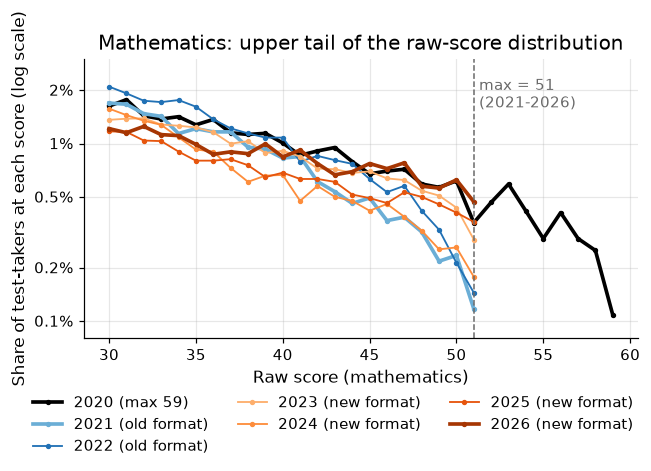

In [4]:
m = eq[eq.subject == "MATH"].groupby(["year", "raw"]).n.sum().reset_index()
m["share"] = 100 * m.n / m.groupby("year").n.transform("sum")
fig, ax = plt.subplots(figsize=(6.5, 3.3))
colors = {2020: "black", 2021: "#6baed6", 2022: "#2171b5",
          2023: "#fdae6b", 2024: "#fd8d3c", 2025: "#e6550d", 2026: "#a63603"}
labels = {2020: "2020 (max 59)", 2021: "2021 (old format)", 2022: "2022 (old format)",
          2023: "2023 (new format)", 2024: "2024 (new format)", 2025: "2025 (new format)", 2026: "2026 (new format)"}
for y in sorted(m.year.unique()):
    d = m[(m.year == y) & (m.raw >= 30)]
    ax.plot(d.raw, d.share, marker="o", ms=2.5, lw=2.4 if y in (2020, 2021, 2026) else 1.2,
            color=colors[y], label=labels[y])
ax.axvline(51, color="dimgray", ls="--", lw=1)
ax.set_yscale("log")
ax.yaxis.set_major_locator(mticker.FixedLocator([0.1, 0.2, 0.5, 1, 2]))
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_ylim(0.08, 3)
ax.text(51.3, 1.6, "max = 51\n(2021-2026)", color="dimgray", fontsize=9.5)
ax.set_xlabel("Raw score (mathematics)")
ax.set_ylabel("Share of test-takers at each score (log scale)")
ax.set_title("Mathematics: upper tail of the raw-score distribution")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.16))
savefig(fig, "fig01_math_upper_tail")

## Figure 2 - Ceiling indicators by subject and year

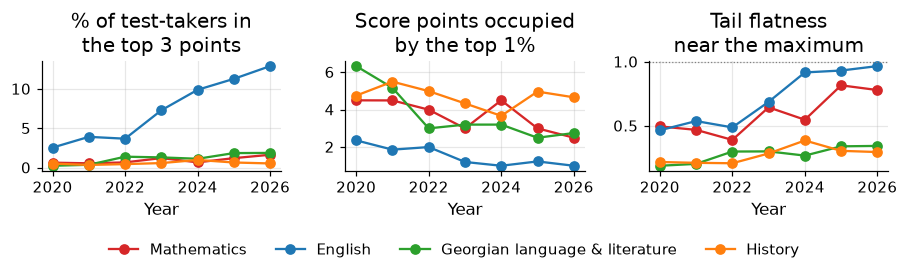

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(8.4, 2.5))
colors = {"MATH": "tab:red", "ENG": "tab:blue", "GEO": "tab:green", "HIST": "tab:orange"}
for s, c in colors.items():
    d = ys[ys.subject == s]
    for ax, col in zip(axes, ["pct_top3", "pts_top1pct", "tail_flatness"]):
        ax.plot(d.year, d[col], marker="o", color=c, label=SUBJ_NAME[s])
axes[0].set_title("% of test-takers in\nthe top 3 points")
axes[1].set_title("Score points occupied\nby the top 1%")
axes[2].set_title("Tail flatness\nnear the maximum")
axes[2].axhline(1, color="grey", lw=0.8, ls=":")
for ax in axes:
    ax.set_xlabel("Year")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=4,
           framealpha=0.85, edgecolor="none")
fig.tight_layout(rect=[0, 0.11, 1, 1])
savefig(fig, "fig02_ceiling_indicators")

## Effect of shortening the tests
Maximum raw score changes: Mathematics 59 -> 51 (2021), Georgian 70 -> 60 (2022), English 80 -> 70 (2023).
Compare the indicators in the year before vs the year of the change.

In [6]:
changes = [("MATH", 2020, 2021), ("GEO", 2021, 2022), ("ENG", 2022, 2023)]
cmp = pd.concat([ys[(ys.subject == s) & ys.year.isin([a, b])] for s, a, b in changes])
cmp = cmp[["subject", "year", "max_raw", "N", "mean_pct", "pct_max", "pct_top3", "pts_top1pct", "pts_top5pct", "tail_flatness"]]
cmp.to_csv(OUT / "t01_test_length_changes.csv", index=False)
cmp.round(2)

,subject,year,max_raw,N,mean_pct,pct_max,pct_top3,pts_top1pct,pts_top5pct,tail_flatness
21,MATH,2020,59.0,11997.0,37.60,0.11,0.65,4.50,13.00,0.50
22,MATH,2021,51.0,11945.0,38.64,0.12,0.57,4.50,12.00,0.47
8,GEO,2021,70.0,33558.0,58.32,0.05,0.38,5.17,9.84,0.20
9,GEO,2022,60.0,36252.0,63.83,0.17,1.41,3.00,6.40,0.30
2,ENG,2022,80.0,33669.0,59.85,0.58,3.69,2.00,4.00,0.49
3,ENG,2023,70.0,36785.0,65.20,1.76,7.31,1.20,3.20,0.69


## Mathematics: how many students share each top score (both versions pooled)

In [7]:
top = (eq[(eq.subject == "MATH") & (eq.raw >= eq.max_raw - 4)]
       .assign(pts_below_max=lambda d: d.max_raw - d.raw)
       .groupby(["year", "pts_below_max"]).n.sum().unstack())
top.columns = [f"max-{c}" if c else "max" for c in top.columns]
top["top3_total"] = top[["max", "max-1", "max-2"]].sum(axis=1)
top.to_csv(OUT / "t01_math_top_counts.csv")
top

,max,max-1,max-2,max-3,max-4,top3_total
year,,,,,,
2020,13,30,35,49,35,78
2021,14,28,26,38,46,68
2022,19,28,43,55,76,90
2023,43,65,76,81,93,184
2024,28,41,40,51,61,109
2025,47,53,59,65,69,159
2026,67,89,80,82,111,236
